In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the uploaded dataset file
df = pd.read_csv(r"C:\Users\nithy\OneDrive\Desktop\nithya\datheon\housing.csv")

# Inspect the dataset
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum())

Dataset shape: (20640, 10)

Column names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

First five rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



Missing values:


longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [3]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


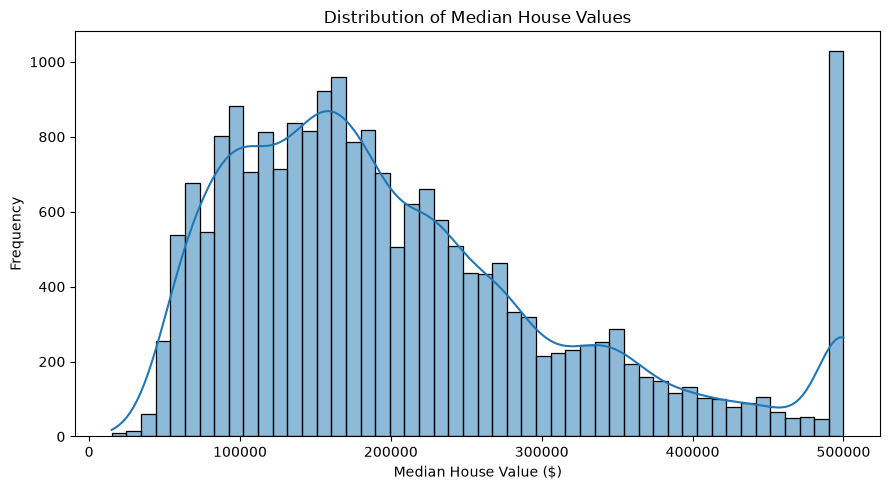

In [5]:

plt.figure(figsize=(9, 5))

sns.histplot(
    df["median_house_value"],
    bins=50,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


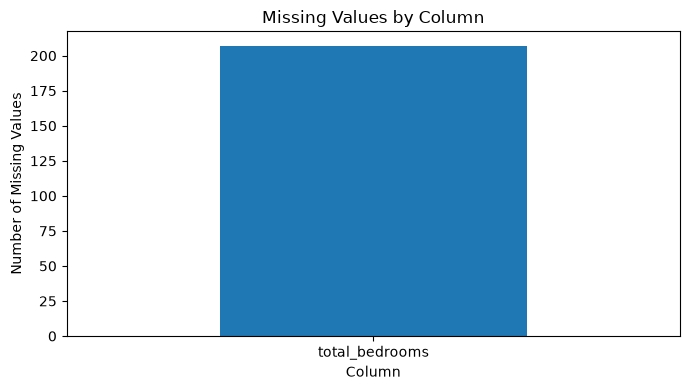

In [6]:

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(7, 4))
missing.plot(kind="bar")
plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


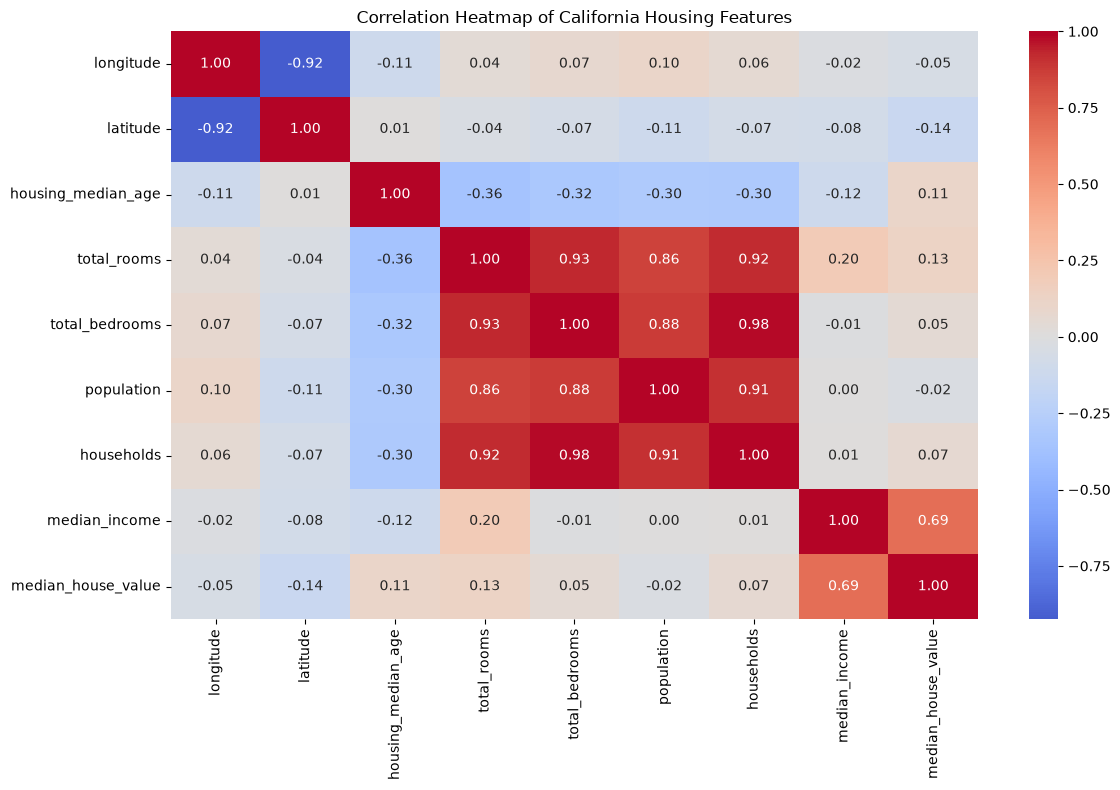

In [7]:

numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of California Housing Features")
plt.tight_layout()
plt.show()


In [8]:

df_model = df.copy()

# Create interaction / ratio features
df_model["bedrooms_per_room"] = (
    df_model["total_bedrooms"] / df_model["total_rooms"]
)

df_model["rooms_per_household"] = (
    df_model["total_rooms"] / df_model["households"]
)

# Check missing values after feature engineering
print("Missing values after feature engineering:")
print(df_model.isnull().sum())

display(df_model.head())


Missing values after feature engineering:
longitude                0
latitude                 0
housing_median_age       0
total_rooms              0
total_bedrooms         207
population               0
households               0
median_income            0
median_house_value       0
ocean_proximity          0
bedrooms_per_room      207
rooms_per_household      0
dtype: int64


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,bedrooms_per_room,rooms_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,0.146591,6.984127
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,0.155797,6.238137
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,0.129516,8.288136
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,0.184458,5.817352
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,0.172096,6.281853


In [9]:

X = df_model.drop(columns=["median_house_value"])
y = df_model["median_house_value"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nCategorical columns:")
print(X.select_dtypes(include="object").columns.tolist())

print("\nNumerical columns:")
print(X.select_dtypes(include="number").columns.tolist())


Feature shape: (20640, 11)
Target shape: (20640,)

Categorical columns:
['ocean_proximity']

Numerical columns:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'bedrooms_per_room', 'rooms_per_household']


C:\Users\nithy\AppData\Local\Temp\ipykernel_36468\4270991233.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X.select_dtypes(include="object").columns.tolist())


In [10]:

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 16512
Testing samples: 4128


In [11]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'bedrooms_per_room', 'rooms_per_household']
Categorical features: ['ocean_proximity']


C:\Users\nithy\AppData\Local\Temp\ipykernel_36468\1692970007.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include="object").columns.tolist()


In [12]:

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



ols_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

ols_model.fit(X_train, y_train)

print("OLS model training completed.")


OLS model training completed.


In [14]:
alpha_values = [0.01, 0.1, 1, 10, 100]

ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

ridge_search = GridSearchCV(
    ridge_pipeline,
    param_grid={"regressor__alpha": alpha_values},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_search.best_params_)
print("Best Ridge CV RMSE:", -ridge_search.best_score_)


Best Ridge alpha: {'regressor__alpha': 1}
Best Ridge CV RMSE: 67802.16313763257


In [16]:

lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Lasso(max_iter=10000))
])

lasso_search = GridSearchCV(
    lasso_pipeline,
    param_grid={"regressor__alpha": alpha_values},
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)

print("Best Lasso alpha:", lasso_search.best_params_)
print("Best Lasso CV RMSE:", -lasso_search.best_score_)


C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best Lasso alpha: {'regressor__alpha': 0.1}
Best Lasso CV RMSE: 67803.17361930685


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.110828e+12, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


In [17]:

models = {
    "OLS": ols_model,
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2 Score": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))


,RMSE,MAE,R2 Score
Model,,,
OLS,69131.853,49642.617,0.635
Ridge,69139.795,49649.342,0.635
Lasso,69131.971,49642.732,0.635


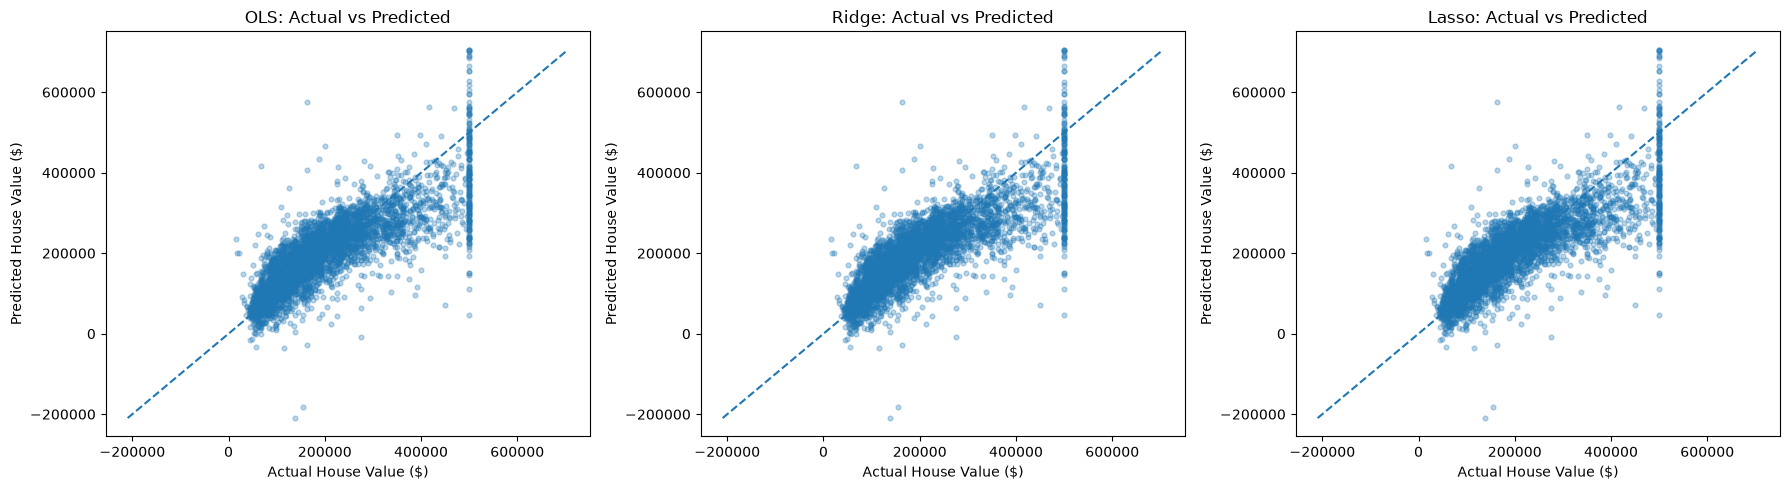

In [18]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.3, s=12)

    # Ideal prediction line
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())

    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        linestyle="--"
    )

    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel("Actual House Value ($)")
    ax.set_ylabel("Predicted House Value ($)")

plt.tight_layout()
plt.show()


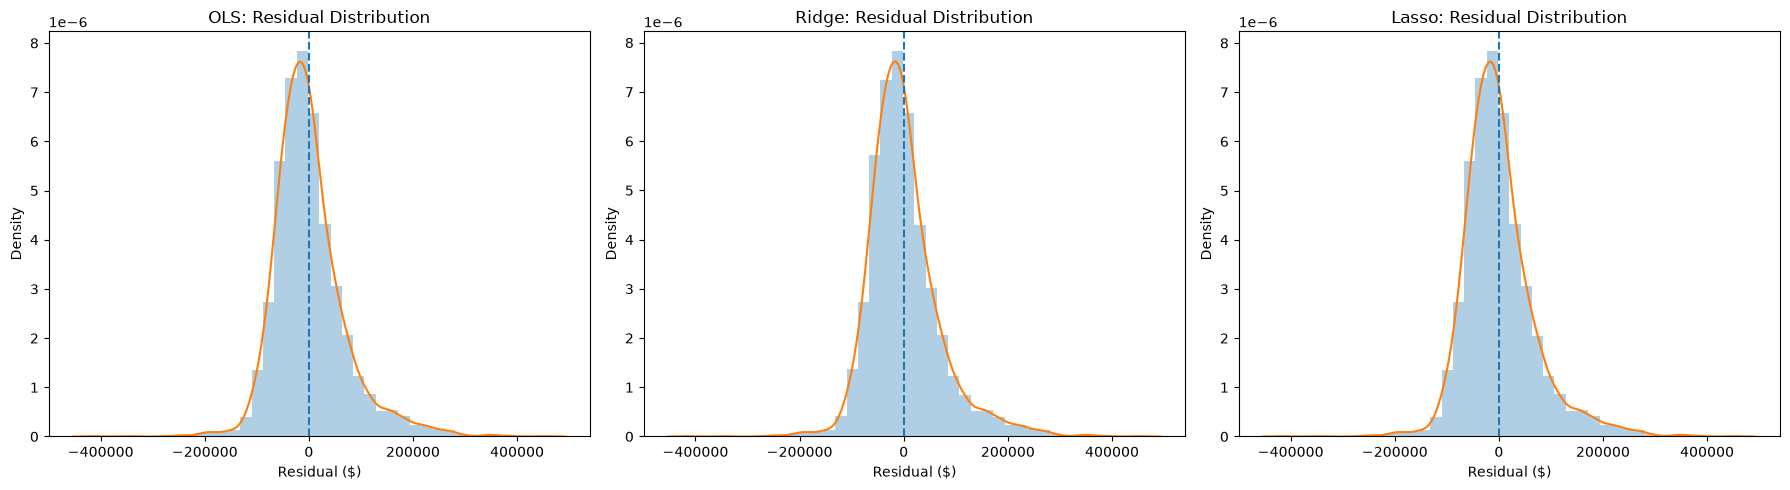

In [19]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    residuals = np.asarray(y_test) - y_pred

    ax.hist(
        residuals,
        bins=40,
        density=True,
        alpha=0.35
    )

    sns.kdeplot(
        x=residuals,
        ax=ax,
        warn_singular=False
    )

    ax.axvline(0, linestyle="--")
    ax.set_title(f"{name}: Residual Distribution")
    ax.set_xlabel("Residual ($)")
    ax.set_ylabel("Density")

plt.tight_layout()
plt.show()


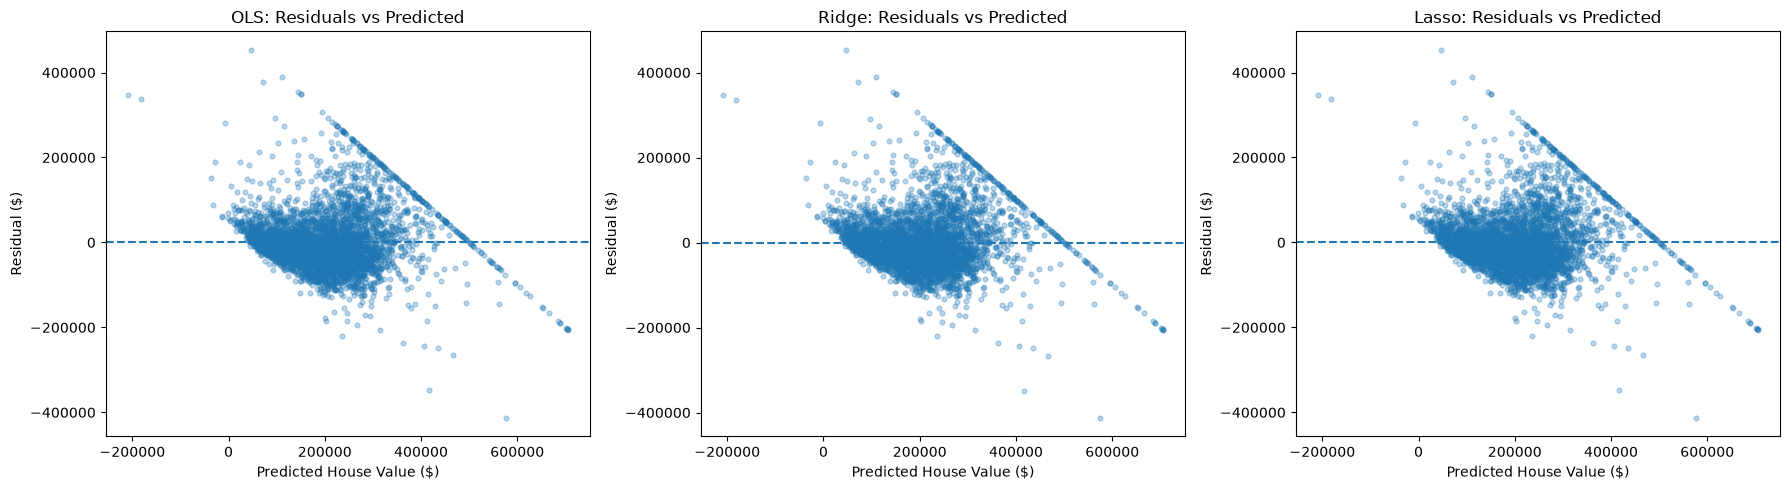

In [20]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    residuals = np.asarray(y_test) - y_pred

    ax.scatter(y_pred, residuals, alpha=0.3, s=12)
    ax.axhline(0, linestyle="--")

    ax.set_title(f"{name}: Residuals vs Predicted")
    ax.set_xlabel("Predicted House Value ($)")
    ax.set_ylabel("Residual ($)")

plt.tight_layout()
plt.show()


In [21]:

best_rmse_model = results_df["RMSE"].idxmin()
best_mae_model = results_df["MAE"].idxmin()
best_r2_model = results_df["R2 Score"].idxmax()

print("Best model by RMSE:", best_rmse_model)
print("Best model by MAE:", best_mae_model)
print("Best model by R²:", best_r2_model)

display(results_df.round(3))


Best model by RMSE: OLS
Best model by MAE: OLS
Best model by R²: OLS


,RMSE,MAE,R2 Score
Model,,,
OLS,69131.853,49642.617,0.635
Ridge,69139.795,49649.342,0.635
Lasso,69131.971,49642.732,0.635


In [22]:

# Extract the fitted regression coefficients
for name in ["OLS", "Ridge", "Lasso"]:
    model = models[name]
    regressor = model.named_steps["regressor"]
    feature_names = model.named_steps["preprocessor"].get_feature_names_out()

    coef_df = pd.DataFrame({
        "Feature": feature_names,
        "Coefficient": regressor.coef_
    })

    coef_df["Absolute Coefficient"] = coef_df["Coefficient"].abs()
    coef_df = coef_df.sort_values("Absolute Coefficient", ascending=False)

    print(f"\n{name} — Top 10 coefficients")
    display(coef_df.head(10).round(3))



OLS — Top 10 coefficients


,Feature,Coefficient,Absolute Coefficient
12,categorical__ocean_proximity_ISLAND,112064.250,112064.250
7,numeric__median_income,78993.698,78993.698
1,numeric__latitude,-56551.230,56551.230
0,numeric__longitude,-56220.417,56220.417
11,categorical__ocean_proximity_INLAND,-53611.810,53611.810
5,numeric__population,-45845.331,45845.331
6,numeric__households,39672.089,39672.089
13,categorical__ocean_proximity_NEAR BAY,-24123.952,24123.952
10,categorical__ocean_proximity_<1H OCEAN,-18696.065,18696.065
8,numeric__bedrooms_per_room,16816.624,16816.624



Ridge — Top 10 coefficients


,Feature,Coefficient,Absolute Coefficient
12,categorical__ocean_proximity_ISLAND,93368.409,93368.409
7,numeric__median_income,78992.525,78992.525
1,numeric__latitude,-56500.531,56500.531
0,numeric__longitude,-56166.263,56166.263
11,categorical__ocean_proximity_INLAND,-48965.474,48965.474
5,numeric__population,-45812.399,45812.399
6,numeric__households,39517.415,39517.415
13,categorical__ocean_proximity_NEAR BAY,-19427.675,19427.675
8,numeric__bedrooms_per_room,16812.080,16812.080
2,numeric__housing_median_age,14148.595,14148.595



Lasso — Top 10 coefficients


,Feature,Coefficient,Absolute Coefficient
12,categorical__ocean_proximity_ISLAND,136333.542,136333.542
7,numeric__median_income,78993.767,78993.767
1,numeric__latitude,-56550.352,56550.352
0,numeric__longitude,-56219.628,56219.628
5,numeric__population,-45844.245,45844.245
6,numeric__households,39669.586,39669.586
11,categorical__ocean_proximity_INLAND,-28929.945,28929.945
8,numeric__bedrooms_per_room,16816.353,16816.353
2,numeric__housing_median_age,14143.395,14143.395
14,categorical__ocean_proximity_NEAR OCEAN,9048.810,9048.810
